In [17]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    make_scorer,
    precision_score,
    recall_score,
)
from xgboost import XGBClassifier

# Original UCI labels are 1-7. This file remaps them to 0-6.
cover_names = [
    "0 Spruce/Fir",
    "1 Lodgepole Pine",
    "2 Ponderosa Pine",
    "3 Cottonwood/Willow",
    "4 Aspen",
    "5 Douglas-fir",
    "6 Krummholz",
]


In [18]:
#read csv file
df = pd.read_csv("forestcovertype.csv", sep=",")


#Explore the dataset
print("Dataset shape:", df.shape)

print("Shape:", df.shape)
print("\nData types:")
display(df.dtypes)
print("\nTarget counts:")
display(df["Cover_Type"].value_counts().sort_index())


# Find missing values and duplicates
print("Missing value:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
constant_columns = df.columns[df.nunique() <= 1].tolist()
print("Constant columns:", constant_columns)

df.head()


Dataset shape: (58101, 55)
Shape: (58101, 55)

Data types:


Elevation                             int64
Aspect                                int64
Slope                                 int64
Horizontal_Distance_To_Hydrology      int64
Vertical_Distance_To_Hydrology        int64
Horizontal_Distance_To_Roadways       int64
Hillshade_9am                         int64
Hillshade_Noon                        int64
Hillshade_3pm                         int64
Horizontal_Distance_To_Fire_Points    int64
Wilderness_Area1                      int64
Wilderness_Area2                      int64
Wilderness_Area3                      int64
Wilderness_Area4                      int64
Soil_Type1                            int64
Soil_Type2                            int64
Soil_Type3                            int64
Soil_Type4                            int64
Soil_Type5                            int64
Soil_Type6                            int64
Soil_Type7                            int64
Soil_Type8                            int64
Soil_Type9                      


Target counts:


Cover_Type
0    21297
1    28248
2     3607
3      259
4      932
5     1706
6     2052
Name: count, dtype: int64

Missing value: 0
Duplicate rows: 0
Constant columns: ['Soil_Type15']


,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,Wilderness_Area1,Wilderness_Area2,Wilderness_Area3,Wilderness_Area4,Soil_Type1,Soil_Type2,Soil_Type3,Soil_Type4,Soil_Type5,Soil_Type6,Soil_Type7,Soil_Type8,Soil_Type9,Soil_Type10,Soil_Type11,Soil_Type12,Soil_Type13,Soil_Type14,Soil_Type15,Soil_Type16,Soil_Type17,Soil_Type18,Soil_Type19,Soil_Type20,Soil_Type21,Soil_Type22,Soil_Type23,Soil_Type24,Soil_Type25,Soil_Type26,Soil_Type27,Soil_Type28,Soil_Type29,Soil_Type30,Soil_Type31,Soil_Type32,Soil_Type33,Soil_Type34,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40,Cover_Type
0,3351,206,27,726,124,3813,192,252,180,2271,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
1,2732,129,7,212,1,1082,231,236,137,912,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1
2,2572,24,9,201,25,957,216,222,142,2191,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
3,2824,69,13,417,39,3223,233,214,110,6478,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
4,2529,84,5,120,9,1092,227,231,139,4983,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1


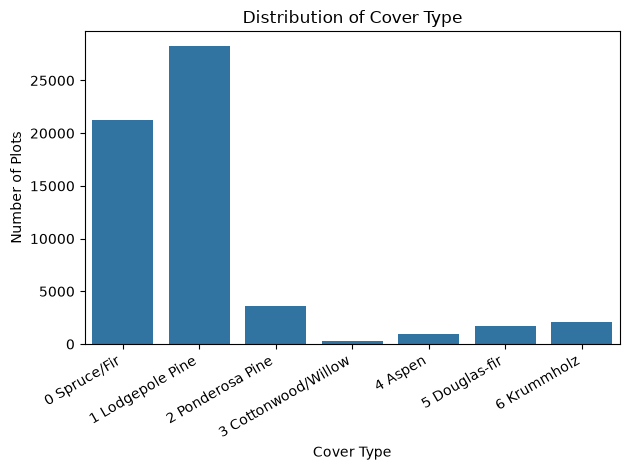

In [19]:
sns.countplot(data=df, x="Cover_Type", order=range(7))
plt.title("Distribution of Cover Type")
plt.xlabel("Cover Type")
plt.ylabel("Number of Plots")
plt.xticks(range(7), cover_names, rotation=30, ha="right")
plt.tight_layout()
plt.show()


## Basic data cleaning

Every column in this file is already an integer. The four wilderness areas and the soil types are stored as 0/1 indicators, so I do not one-hot encode them again. There are no missing values and no duplicate rows.

`Soil_Type15` is 0 on every plot in this 10% sample, so that column cannot split a tree. I drop it and keep every row.

Cover type is unbalanced. Spruce/Fir and Lodgepole Pine are most of the plots, and Cottonwood/Willow has only a few hundred. Tree splits do not need the numeric columns to be scaled, because a split only compares one feature at a time.


In [20]:
df = df.drop(columns=["Soil_Type15"]).copy()
print("Shape after dropping the constant soil column:", df.shape)

X = df.drop(columns="Cover_Type")
y = df["Cover_Type"]
print(X.shape)
print(y.value_counts().sort_index())

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
print("Training shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("\nTraining proportions:")
print(y_train.value_counts(normalize=True).sort_index())
print("\nTest proportions:")
print(y_test.value_counts(normalize=True).sort_index())


Shape after dropping the constant soil column: (58101, 54)
(58101, 53)
Cover_Type
0    21297
1    28248
2     3607
3      259
4      932
5     1706
6     2052
Name: count, dtype: int64
Training shape: (46480, 53)
Test shape: (11621, 53)

Training proportions:
Cover_Type
0    0.366545
1    0.486188
2    0.062070
3    0.004454
4    0.016050
5    0.029367
6    0.035327
Name: proportion, dtype: float64

Test proportions:
Cover_Type
0    0.366578
1    0.486189
2    0.062129
3    0.004475
4    0.016006
5    0.029343
6    0.035281
Name: proportion, dtype: float64


In [21]:
categorical_columns = X_train.select_dtypes(include=["object", "str", "string"]).columns.tolist()
numerical_columns = X_train.select_dtypes(include="number").columns.tolist()
print("Categorical columns:", categorical_columns)
print("Numerical columns:", numerical_columns)


Categorical columns: []
Numerical columns: ['Elevation', 'Aspect', 'Slope', 'Horizontal_Distance_To_Hydrology', 'Vertical_Distance_To_Hydrology', 'Horizontal_Distance_To_Roadways', 'Hillshade_9am', 'Hillshade_Noon', 'Hillshade_3pm', 'Horizontal_Distance_To_Fire_Points', 'Wilderness_Area1', 'Wilderness_Area2', 'Wilderness_Area3', 'Wilderness_Area4', 'Soil_Type1', 'Soil_Type2', 'Soil_Type3', 'Soil_Type4', 'Soil_Type5', 'Soil_Type6', 'Soil_Type7', 'Soil_Type8', 'Soil_Type9', 'Soil_Type10', 'Soil_Type11', 'Soil_Type12', 'Soil_Type13', 'Soil_Type14', 'Soil_Type16', 'Soil_Type17', 'Soil_Type18', 'Soil_Type19', 'Soil_Type20', 'Soil_Type21', 'Soil_Type22', 'Soil_Type23', 'Soil_Type24', 'Soil_Type25', 'Soil_Type26', 'Soil_Type27', 'Soil_Type28', 'Soil_Type29', 'Soil_Type30', 'Soil_Type31', 'Soil_Type32', 'Soil_Type33', 'Soil_Type34', 'Soil_Type35', 'Soil_Type36', 'Soil_Type37', 'Soil_Type38', 'Soil_Type39', 'Soil_Type40']


In [22]:
# No categorical columns are left. Fill any numeric gap with the median.
# This sample has no missing values, so the imputer does not change the numbers.
numerical_pipeline = make_pipeline(
    SimpleImputer(strategy="median")
)

preprocessor = ColumnTransformer([
    ("numerical", numerical_pipeline, numerical_columns)
])


In [23]:
models = {
    "ID3-style (Entropy)": DecisionTreeClassifier(
        criterion="entropy",
        max_depth=6,
        min_samples_leaf=10,
        random_state=42
    ),

    "CART (Gini)": DecisionTreeClassifier(
        criterion="gini",
        max_depth=6,
        min_samples_leaf=10,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=4,
        eval_metric="mlogloss",
        random_state=42,
        n_jobs=-1
    )
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


## Cross-validation

I used stratified 5-fold cross-validation on the training set. Five folds is a useful balance: each validation fold still contains about 40 Cottonwood/Willow plots, while the average over five folds is less sensitive to one lucky split. 

In [24]:
# If a fold never predicts a cover type, count that type's precision as 0.
scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, average="macro", zero_division=0),
    "recall": make_scorer(recall_score, average="macro", zero_division=0),
    "f1": make_scorer(f1_score, average="macro", zero_division=0),
}

cv_rows = []
for model_name, model in models.items():
    model_pipeline = make_pipeline(preprocessor, model)
    scores = cross_validate(
        model_pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=1
    )
    cv_rows.append({
        "Model": model_name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Macro Precision": scores["test_precision"].mean(),
        "Macro Recall": scores["test_recall"].mean(),
        "Macro F1": scores["test_f1"].mean(),
    })
    print(
        f"{model_name}: "
        f"accuracy = {scores['test_accuracy'].mean():.4f}, "
        f"macro F1 = {scores['test_f1'].mean():.4f}"
    )

cv_df = pd.DataFrame(cv_rows)
display(cv_df.round(4))


ID3-style (Entropy): accuracy = 0.7158, macro F1 = 0.5427
CART (Gini): accuracy = 0.7198, macro F1 = 0.5070
Random Forest: accuracy = 0.7425, macro F1 = 0.4851
Gradient Boosting: accuracy = 0.7690, macro F1 = 0.6603
XGBoost: accuracy = 0.7627, macro F1 = 0.6255


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,ID3-style (Entropy),0.7158,0.7028,0.5127,0.5427
1,CART (Gini),0.7198,0.6625,0.4935,0.5070
2,Random Forest,0.7425,0.6852,0.4477,0.4851
3,Gradient Boosting,0.7690,0.7497,0.6249,0.6603
4,XGBoost,0.7627,0.7658,0.5880,0.6255


In [25]:
fitted_models = {}
test_predictions = {}

for model_name, model in models.items():
    model_pipeline = make_pipeline(preprocessor, model)
    model_pipeline.fit(X_train, y_train)
    predictions = model_pipeline.predict(X_test)

    fitted_models[model_name] = model_pipeline
    test_predictions[model_name] = predictions


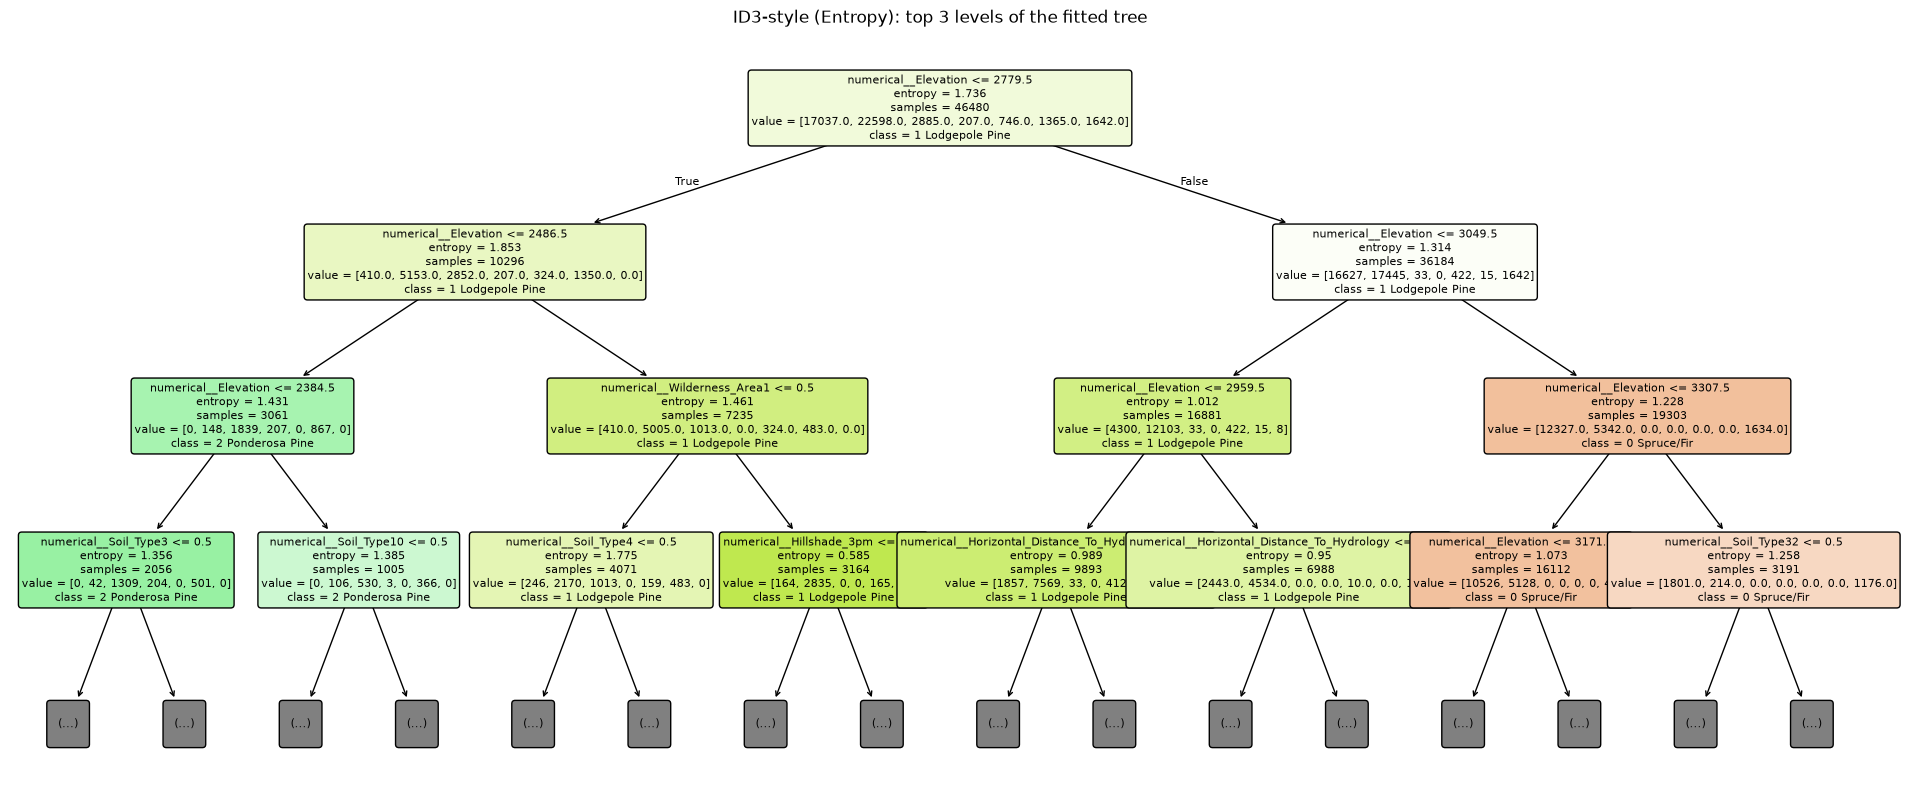

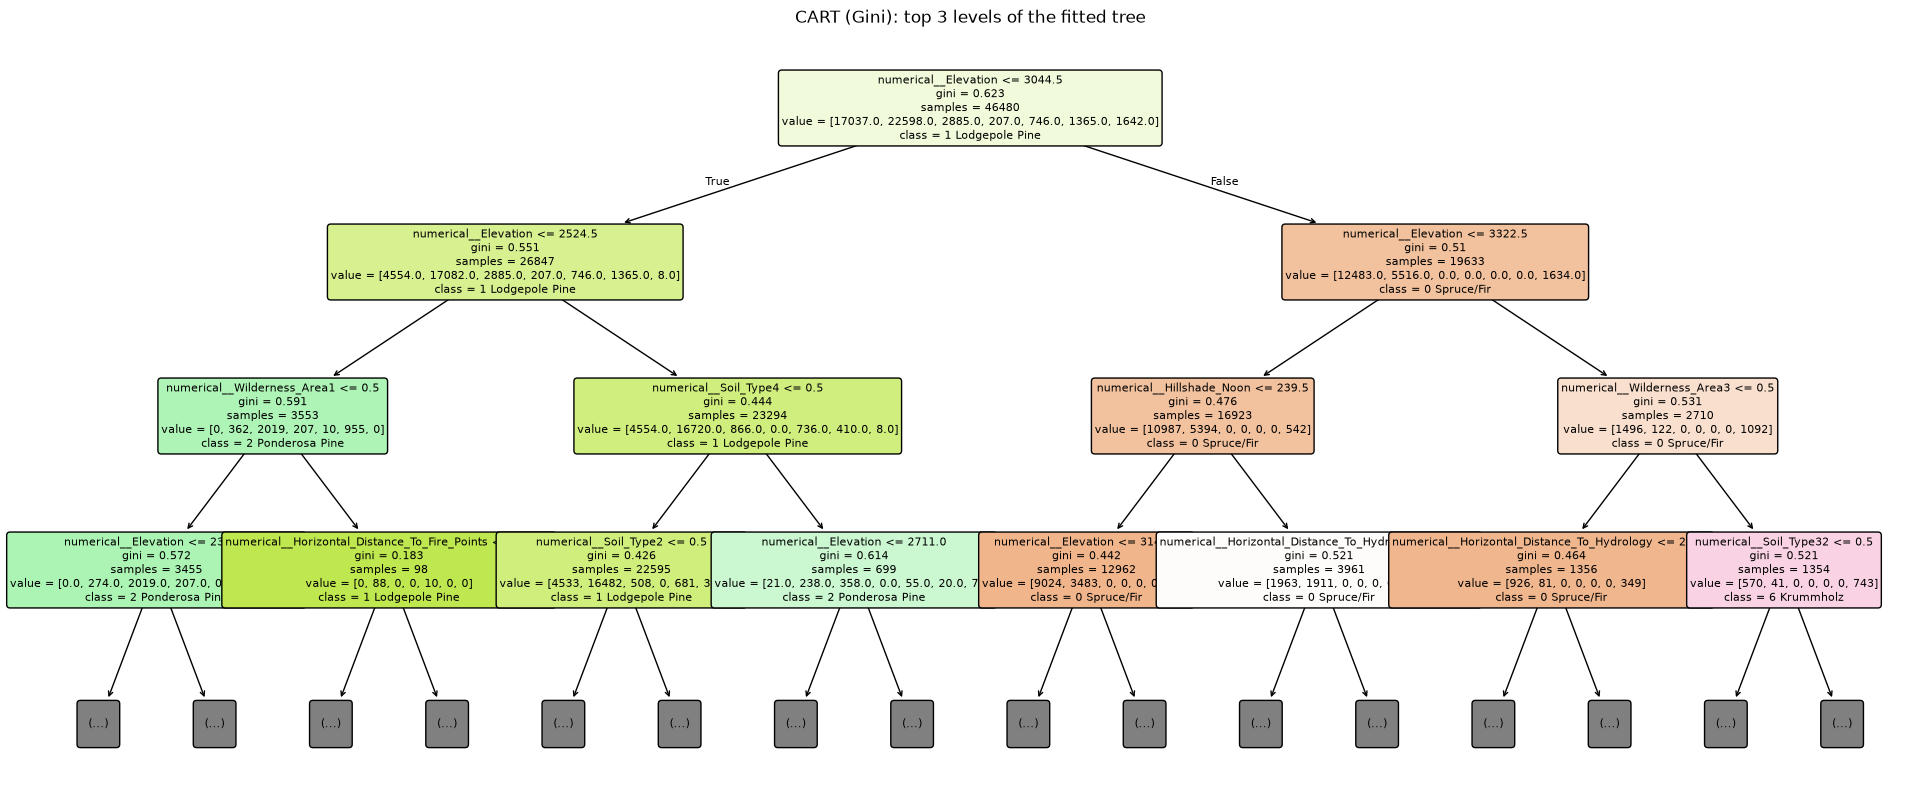

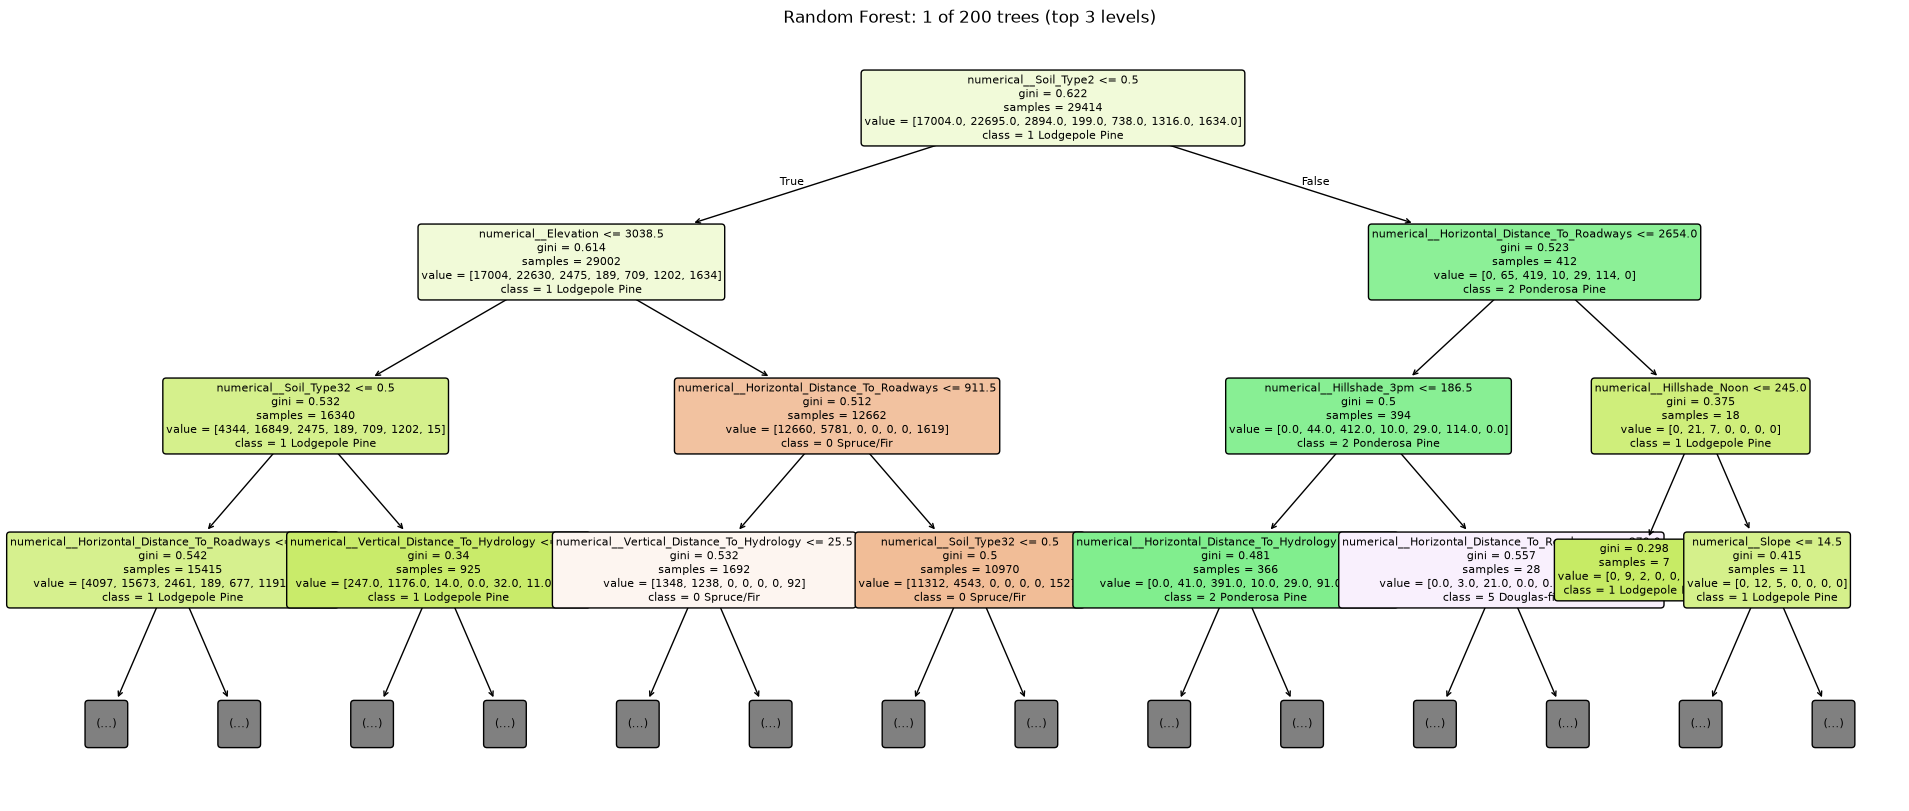

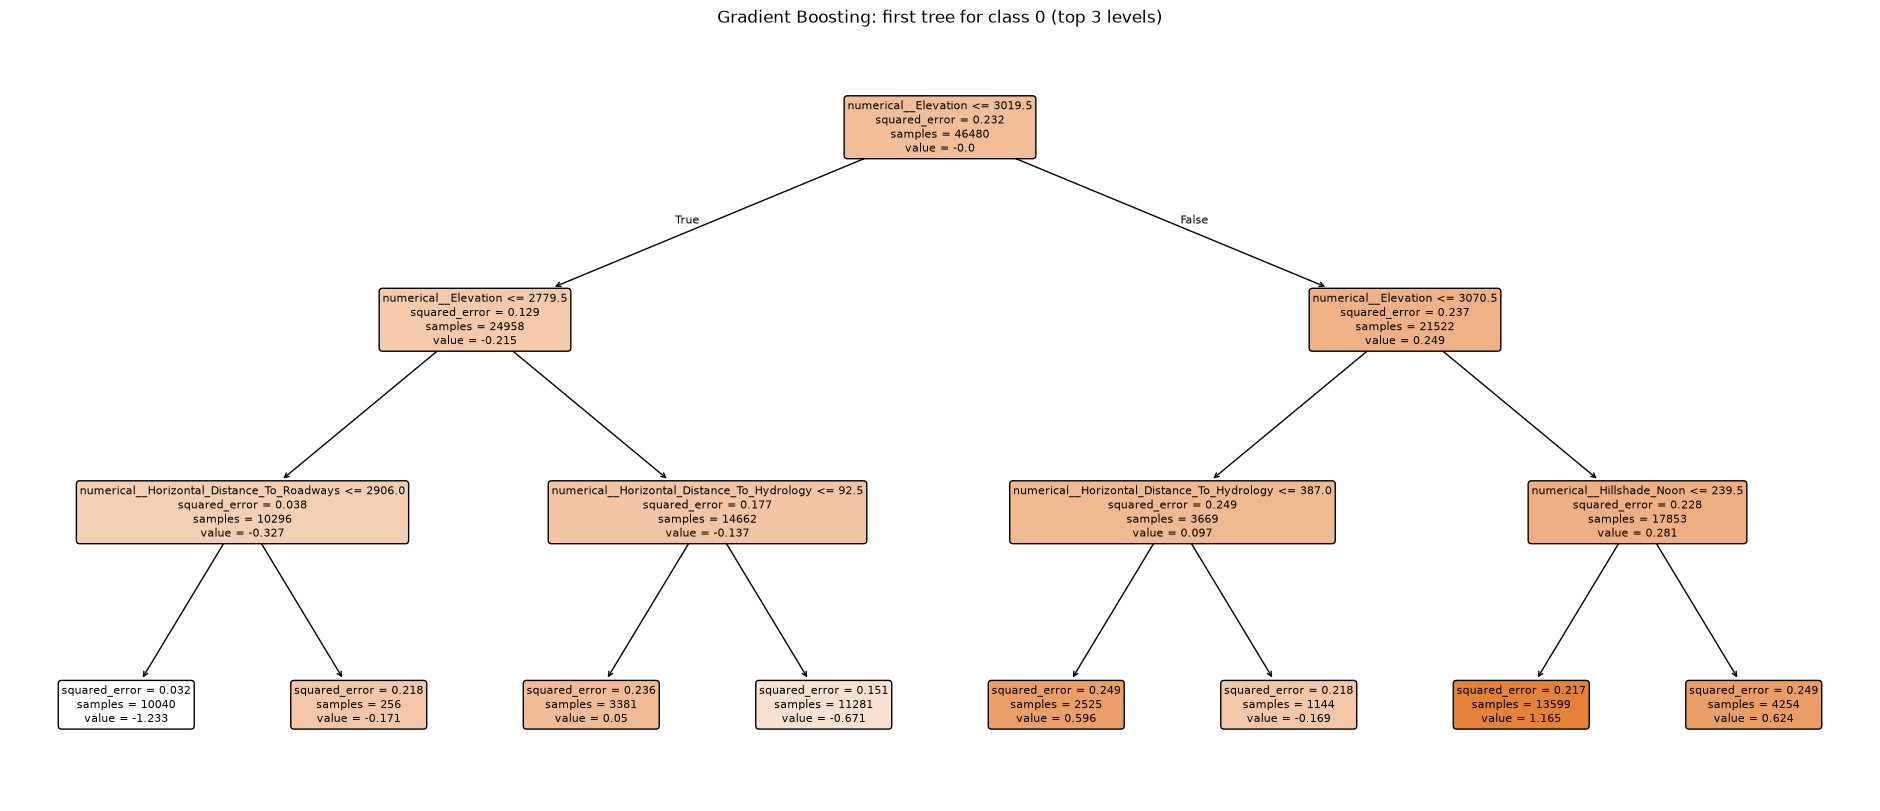

In [26]:
for model_name, pipeline in fitted_models.items():
    model = pipeline.steps[-1][1]
    feature_names = pipeline.named_steps["columntransformer"].get_feature_names_out()

    if model_name == "Random Forest":
        tree = model.estimators_[0]
        title = "Random Forest: 1 of 200 trees (top 3 levels)"
        class_names = cover_names
    elif model_name == "Gradient Boosting":
        tree = model.estimators_[0, 0]
        title = "Gradient Boosting: first tree for class 0 (top 3 levels)"
        class_names = None
    elif model_name == "XGBoost":
        continue
    else:
        tree = model
        title = f"{model_name}: top 3 levels of the fitted tree"
        class_names = cover_names

    plt.figure(figsize=(24, 10))
    plot_tree(
        tree,
        max_depth=3,
        feature_names=feature_names,
        class_names=class_names,
        filled=True,
        rounded=True,
        fontsize=8,
    )
    plt.title(title)
    plt.show()


In [27]:
report_rows = []
per_class_f1 = []

for model_name, predictions in test_predictions.items():
    report = classification_report(
        y_test,
        predictions,
        target_names=cover_names,
        zero_division=0,
        output_dict=True,
    )
    report_rows.append({
        "Model": model_name,
        "Accuracy": report["accuracy"],
        "Macro Precision": report["macro avg"]["precision"],
        "Macro Recall": report["macro avg"]["recall"],
        "Macro F1": report["macro avg"]["f1-score"],
        "Weighted Precision": report["weighted avg"]["precision"],
        "Weighted Recall": report["weighted avg"]["recall"],
        "Weighted F1": report["weighted avg"]["f1-score"],
    })
    f1_row = {"Model": model_name}
    for name in cover_names:
        f1_row[name] = report[name]["f1-score"]
    per_class_f1.append(f1_row)

report_df = pd.DataFrame(report_rows)
f1_df = pd.DataFrame(per_class_f1)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)
pd.set_option("display.max_colwidth", None)
display(report_df.round(4))
display(f1_df.round(4))


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted Precision,Weighted Recall,Weighted F1
0,ID3-style (Entropy),0.7174,0.7137,0.5112,0.5315,0.7191,0.7174,0.7053
1,CART (Gini),0.7214,0.6473,0.5264,0.5485,0.7150,0.7214,0.7107
2,Random Forest,0.7468,0.6947,0.4811,0.5234,0.7396,0.7468,0.7321
3,Gradient Boosting,0.7716,0.7561,0.6303,0.6655,0.7712,0.7716,0.7676
4,XGBoost,0.7657,0.7718,0.6214,0.6521,0.7650,0.7657,0.7588


,Model,0 Spruce/Fir,1 Lodgepole Pine,2 Ponderosa Pine,3 Cottonwood/Willow,4 Aspen,5 Douglas-fir,6 Krummholz
0,ID3-style (Entropy),0.6988,0.7663,0.7345,0.5789,0.1932,0.2020,0.5469
1,CART (Gini),0.6812,0.7743,0.7624,0.5495,0.0510,0.3554,0.6658
2,Random Forest,0.7355,0.7882,0.7755,0.5070,0.0000,0.2350,0.6226
3,Gradient Boosting,0.7525,0.8025,0.7930,0.6200,0.3697,0.5078,0.8130
4,XGBoost,0.7488,0.8010,0.7756,0.7921,0.2973,0.3611,0.7890


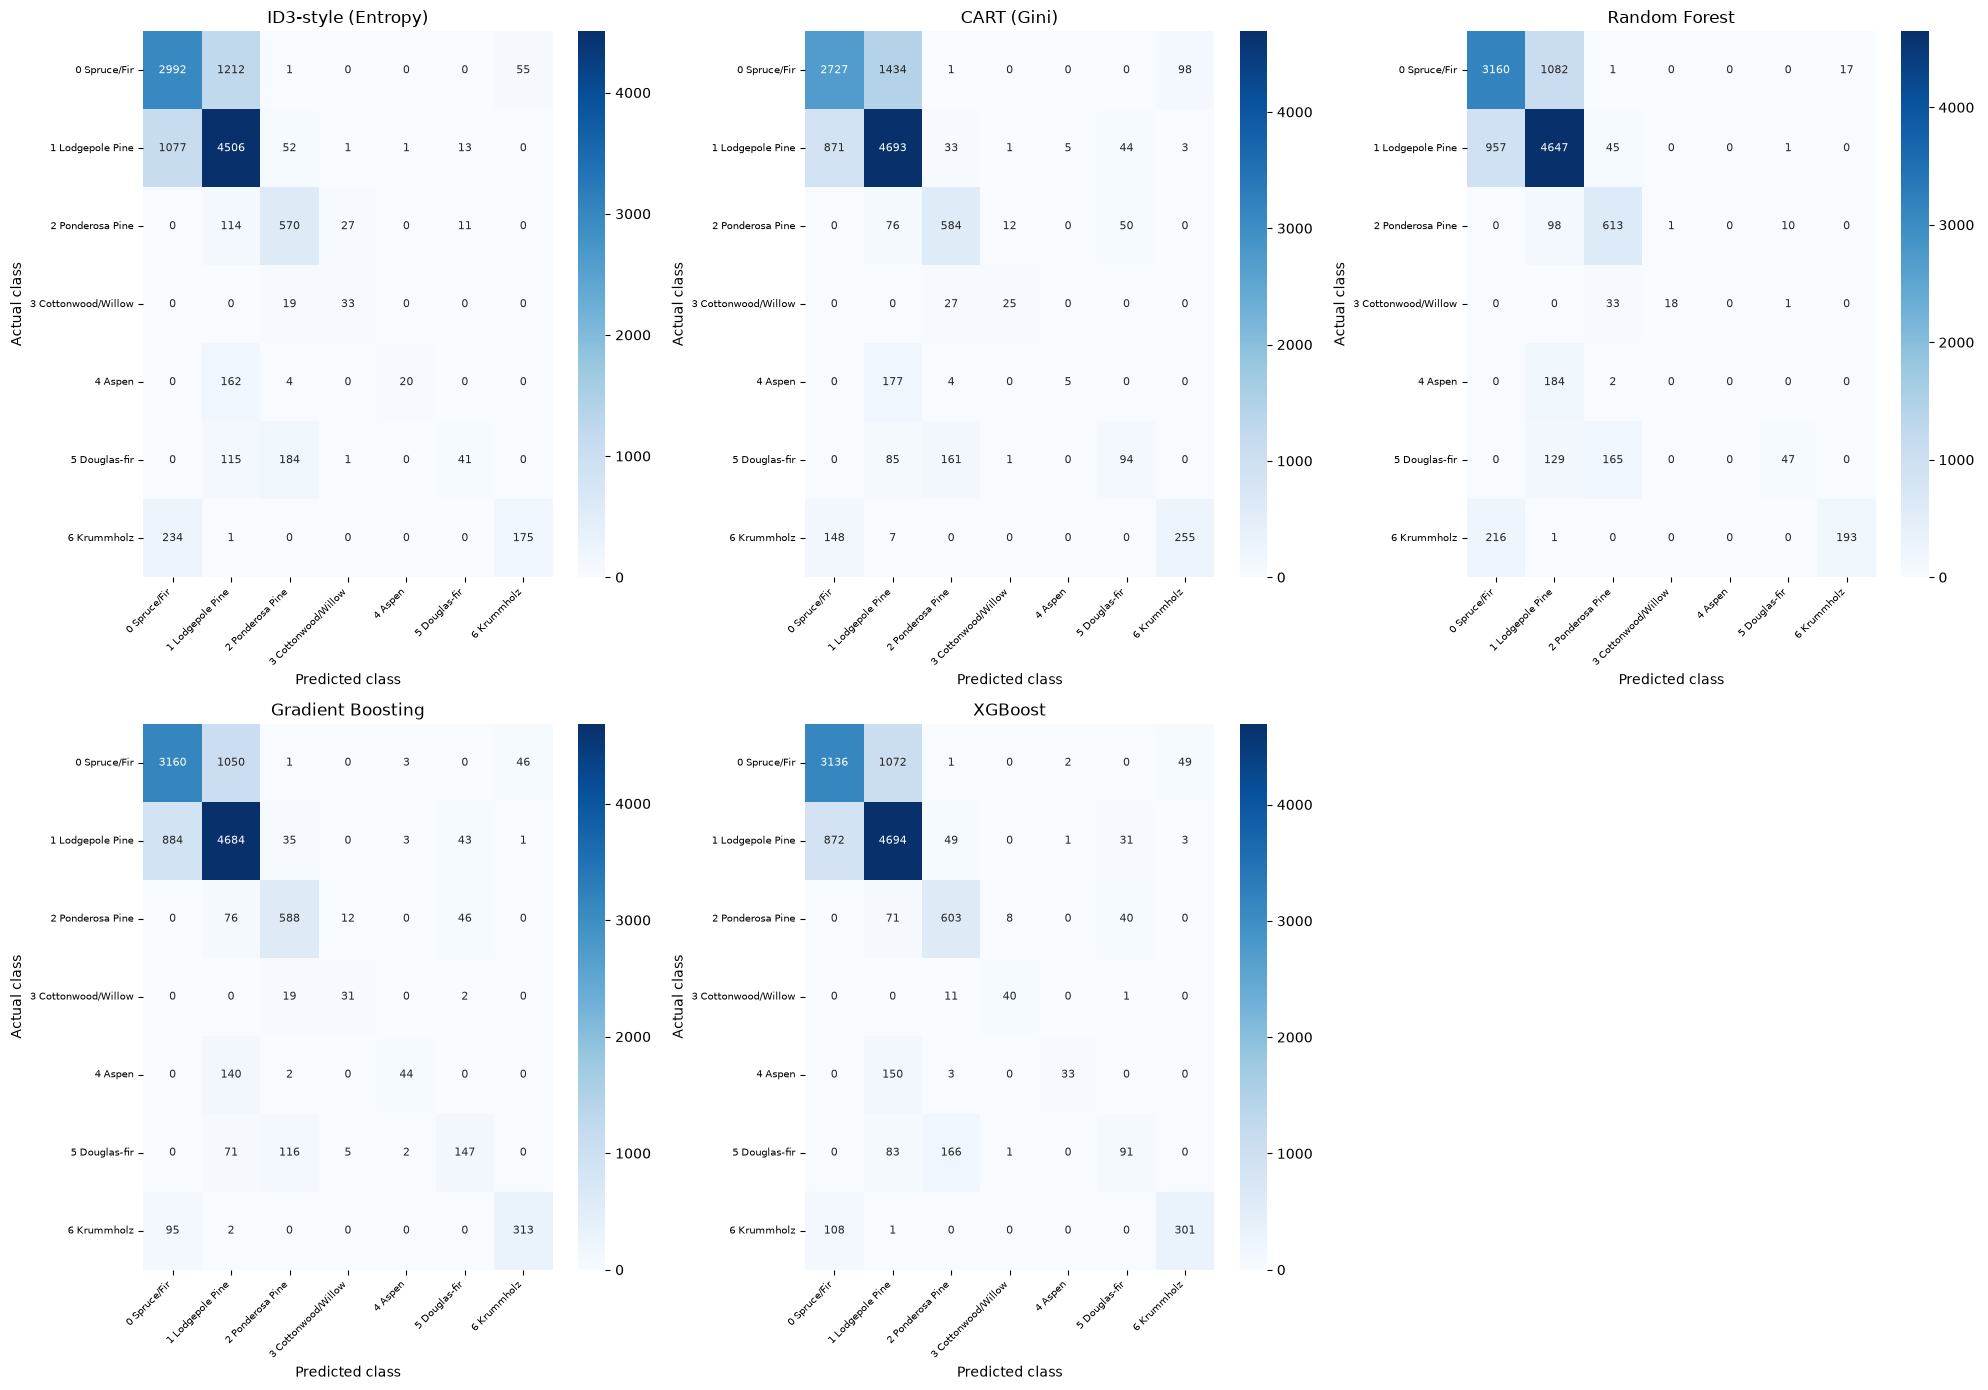

In [28]:
fig, axes = plt.subplots(2, 3, figsize=(20, 14))
axes = axes.flatten()

for index, (model_name, predictions) in enumerate(test_predictions.items()):
    cm = confusion_matrix(y_test, predictions, labels=range(7))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[index], annot_kws={"size": 8})
    axes[index].set_title(model_name)
    axes[index].set_xlabel("Predicted class")
    axes[index].set_ylabel("Actual class")
    axes[index].set_xticklabels(cover_names, rotation=45, ha="right", fontsize=7)
    axes[index].set_yticklabels(cover_names, rotation=0, fontsize=7)

axes[-1].axis("off")
plt.tight_layout()
plt.show()


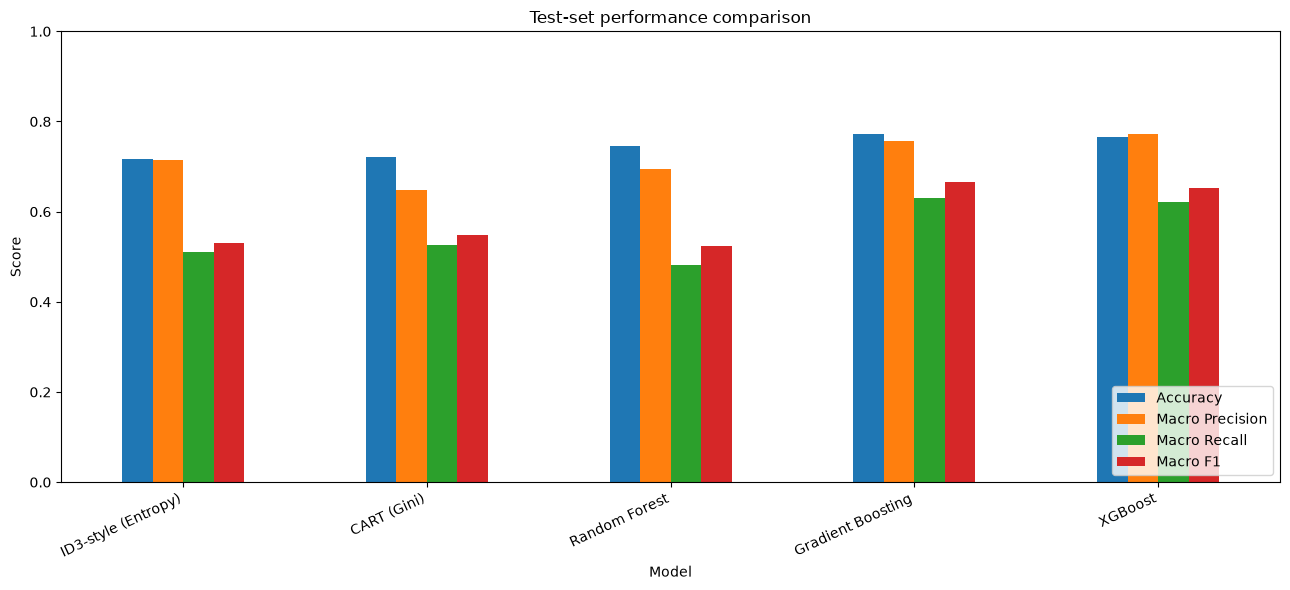

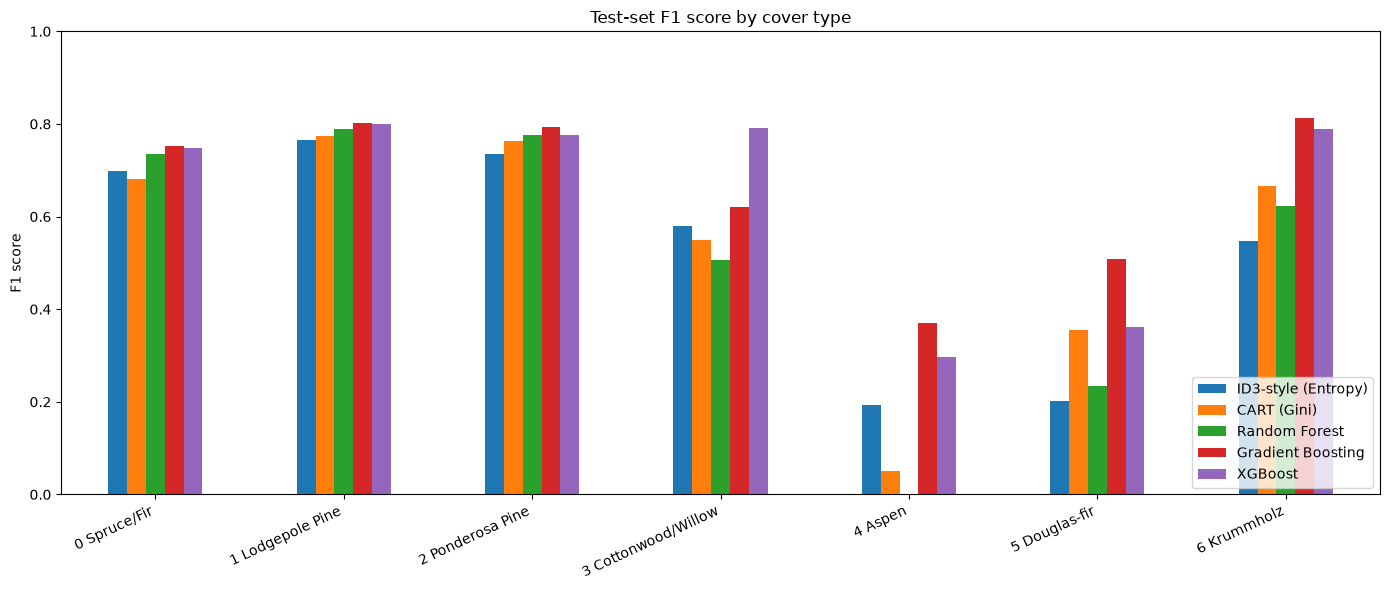

In [29]:
comparison = report_df.set_index("Model")[[
    "Accuracy", "Macro Precision", "Macro Recall", "Macro F1"
]]

comparison.plot(kind="bar", figsize=(13, 6))
plt.title("Test-set performance comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=25, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

f1_df.set_index("Model").T.plot(kind="bar", figsize=(14, 6))
plt.title("Test-set F1 score by cover type")
plt.ylabel("F1 score")
plt.ylim(0, 1)
plt.xticks(rotation=25, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


## Meaning and limitations of the metrics

- **Accuracy** is the proportion of plots whose cover type is predicted correctly. It is the natural score if the goal is a correct label on a typical plot. Its limitation here is the imbalance: Spruce/Fir and Lodgepole Pine are about 85% of the data, so a model can look accurate while missing the rare types.
- **Precision** for a cover type is the proportion of plots predicted as that type that really are that type. It matters when a false label would put the wrong species on a map. A model can raise precision by predicting a rare type only when it is very sure, and then miss many true plots of that type.
- **Recall** for a cover type is the proportion of actual plots of that type that the model finds. It matters when the goal is to locate less common communities, such as Cottonwood/Willow or Aspen. Raising recall usually adds more false positives.
- **F1** is the harmonic mean of precision and recall. I report the macro average, which gives each of the seven types the same weight, and the weighted average, which weights types by how many test plots they have. Macro F1 is the more relevant summary for this dataset. Weighted F1 mostly repeats the accuracy story of the two common types. F1 does not count true negatives, and it treats precision and recall as equally important.


In [30]:
metric_columns = ["Accuracy", "Macro Precision", "Macro Recall", "Macro F1", "Weighted F1"]

for metric in metric_columns:
    best_row = report_df.loc[report_df[metric].idxmax()]
    print(f"Algorithm {best_row['Model']} is better for {metric} ({best_row[metric]:.4f})")

print()
for name in cover_names:
    best_row = f1_df.loc[f1_df[name].idxmax()]
    print(f"Algorithm {best_row['Model']} is better for {name} F1 ({best_row[name]:.4f})")


Algorithm Gradient Boosting is better for Accuracy (0.7716)
Algorithm XGBoost is better for Macro Precision (0.7718)
Algorithm Gradient Boosting is better for Macro Recall (0.6303)
Algorithm Gradient Boosting is better for Macro F1 (0.6655)
Algorithm Gradient Boosting is better for Weighted F1 (0.7676)

Algorithm Gradient Boosting is better for 0 Spruce/Fir F1 (0.7525)
Algorithm Gradient Boosting is better for 1 Lodgepole Pine F1 (0.8025)
Algorithm Gradient Boosting is better for 2 Ponderosa Pine F1 (0.7930)
Algorithm XGBoost is better for 3 Cottonwood/Willow F1 (0.7921)
Algorithm Gradient Boosting is better for 4 Aspen F1 (0.3697)
Algorithm Gradient Boosting is better for 5 Douglas-fir F1 (0.5078)
Algorithm Gradient Boosting is better for 6 Krummholz F1 (0.8130)
